# Résultats sur DONNÉES FICTIVES — détection des incidents de cassettes

Exécuté sur une table **simulée** au format de la recette `cassettes_terminal_heure.sql` : 40 terminaux, du 01/09 au 08/11/2026, une ligne par terminal et par heure. **Les chiffres n'ont aucune valeur réelle.**

Incidents injectés :
- **T12301** (code regate 12301) : inversion des cassettes 10 € / 20 € du 04/11 12 h au 05/11 12 h, perte simulée 5 740 €, chargement du terminal tous les jours à 12 h. *Hypothèse de simulation* : le terminal sollicite davantage la position « 10 € » et des clients refont un retrait.
- **T75020** : valeur déclarée de la position 1 passée de 20 € à 10 € le 30/10 de 9 h à 18 h (paramétrage).
- **T69011** : cassette position 3 bloquée le 02/11 de 8 h à 18 h.
- **T13004** : retraits répétés par la même carte le 31/10 de 14 h à 20 h (signal faible).
- **T33010** : nouveau plan de cassettes à partir du 28/10 (changement légitime).
- T12302 à T12306 et 30 autres terminaux : normaux.

La section 1 a été réglée pour l'exécution : `CAS_CONNU = {"debut": "2026-11-04 12:00", "fin": "2026-11-05 12:00", "prefixe_site": "123", "perte_declaree": 5740}`.


# Détection des incidents de cassettes (inversion de coupures, paramétrage, cassette bloquée)

**Point de départ.** Une inversion de cassettes (billets de 10 € chargés à la place des 20 €, ou l'inverse) est rare,
coûteuse, et ne se voit pas dans le montant des retraits : le terminal enregistre ce qu'il **croit** distribuer.

**Ce qu'on cherche, terminal par terminal et heure par heure**, en comparant chaque fenêtre de 24 h à l'habitude du terminal
sur les 4 semaines précédentes :
1. **Billets sortis par cassette** : une cassette qui sort beaucoup plus (ou beaucoup moins) de billets que
   d'habitude au même jour de semaine et aux mêmes heures, et sa **part** dans le total des billets.
2. **Valeur déclarée d'une cassette modifiée** : la position 1 vaut d'habitude 20 € et passe à 10 €.
3. **Retraits répétés par la même carte** dans les 10 minutes : clients qui n'ont pas reçu le bon montant.

Une cassette **inactive** en temps normal (par exemple la cassette de 5 €, qui ne distribue plus) est écartée
des calculs ; si elle se remet à sortir des billets, c'est un signal à part.

Un seuil fixe ne convient pas à tous les terminaux : chaque signal est comparé au **maximum atteint par ce même terminal
pendant ses 4 semaines de référence**. Un événement est signalé quand le terminal fait ce qu'il n'a jamais fait.

**Chargements.** L'encaisse théorique baisse à chaque retrait et remonte d'un coup quand le terminal est rechargé.
Une inversion de cassettes se produit forcément à un chargement : une anomalie de répartition qui commence juste
après une remontée de l'encaisse renforce fortement la piste de l'inversion.

**Perte estimée.** Si une inversion 10 € / 20 € est confirmée, la perte vaut 10 € x (billets sortis des positions
« 10 € » - billets sortis des positions « 20 € ») sur la période : chaque billet sorti d'une position « 10 € »
était un 20 € (perte de 10 €), chaque billet sorti d'une position « 20 € » était un 10 € (gain de 10 €).

Entrée : dataset produit par la recette `cassettes_terminal_heure.sql` (une ligne par terminal, jour et heure).
Exécuter les cellules dans l'ordre. Seule la section 1 se modifie.

## 0. Imports

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

try:
    from scipy.stats import chi2
except ImportError:          # scipy absent : seuil théorique remplacé par le maximum de référence seul
    chi2 = None
pd.set_option("display.max_columns", 60)

## 1. Configuration

In [2]:
# ============================================================================================================
# BLOC À COMPLÉTER
# ============================================================================================================
DATASET_CASSETTES = "cassettes_terminal_heure"     # sortie de la recette cassettes_terminal_heure.sql
DEBUT_ANALYSE = "2026-10-26"                  # début de la période examinée (la référence est avant)
CAS_CONNU = {"debut": "2026-11-04 12:00", "fin": "2026-11-05 12:00", "prefixe_site": "123", "perte_declaree": 5740, "jours_autour": 2}                              # cas confirmé pour valider la méthode, ex. :
# CAS_CONNU = {"debut": "AAAA-MM-JJ HH:MM", "fin": "AAAA-MM-JJ HH:MM",
#              "prefixe_site": "123", "perte_declaree": 5000}
DATASET_SORTIE_EVENEMENTS = None              # ex. "incidents_cassettes" (dataset à créer dans le Flow)

# ============================================================================================================
# PARAMÈTRES DE LA MÉTHODE
# ============================================================================================================
JOURS_REFERENCE = 28          # habitude du terminal : 4 semaines avant DEBUT_ANALYSE
FENETRE_HEURES = 24           # fenêtre glissante examinée
MIN_BILLETS_FENETRE = 100     # en dessous, la répartition n'est pas interprétable
ECART_PART_MIN = 0.10         # écart minimal de part d'une position (10 points)
MARGE_REFERENCE = 1.5         # le signal doit dépasser 1,5 fois le maximum atteint en référence
MIN_REPETES = 5               # nombre minimal de retraits répétés dans la fenêtre
PART_ACTIVE_MIN = 0.01        # une cassette sortant moins de 1 % des billets en référence est considérée inactive
RATIO_SUR = 2.0               # cassette sur-sollicitée : au moins 2 fois ses billets habituels sur 24 h...
MIN_EXCES_BILLETS = 60        # ... et au moins 60 billets de plus que d'habitude
RATIO_SOUS = 0.3              # cassette sous-utilisée : au plus 30 % de ses billets habituels...
MIN_BILLETS_HABITUELS = 60    # ... quand elle en sort d'habitude au moins 60 sur 24 h
MIN_BILLETS_REACTIVATION = 20 # cassette inactive qui sort au moins 20 billets sur 24 h
POSITIONS = [1, 2, 3, 4]

## 2. Fonctions d'affichage

In [3]:
BLEU, GRIS, GRIS_CLAIR, ORANGE, ENCRE = "#2a78d6", "#8a8984", "#d9d8d3", "#eb6834", "#0b0b0b"
COULEUR_COUPURE = {10: ORANGE, 20: BLEU, 50: GRIS, 5: ENCRE, 100: ENCRE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ececea", "grid.linewidth": 0.8, "axes.edgecolor": "#b5b4ae",
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
CSS = """<style>
.kpi-grille{display:flex;flex-wrap:wrap;gap:10px;margin:6px 0 14px}
.kpi{border:1px solid #e3e2de;border-radius:8px;padding:10px 14px;min-width:150px;background:#fcfcfb}
.kpi .v{font-size:22px;font-weight:700;color:#0b0b0b}.kpi .l{font-size:12px;color:#52514e}
table.t{border-collapse:collapse;font-size:12px;margin:4px 0 12px}
table.t th{background:#f3f2ef;color:#0b0b0b;text-align:left;padding:5px 9px;border-bottom:2px solid #d9d8d3}
table.t td{padding:4px 9px;border-bottom:1px solid #ecebe8;text-align:right}
table.t td.txt{text-align:left}
.note{color:#52514e;font-size:12.5px;margin:2px 0 10px;max-width:900px}
</style>"""


def echapper(texte):
    """Texte sûr dans du HTML."""
    return str(texte).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")


def formater(v):
    """Nombre lisible : séparateur de milliers, 1 décimale au plus."""
    if isinstance(v, (bool, np.bool_)):
        return "oui" if v else "non"
    if isinstance(v, (int, np.integer)):
        return "{:,}".format(int(v)).replace(",", " ")
    if isinstance(v, (float, np.floating)):
        if np.isnan(v):
            return "–"
        return "{:,.1f}".format(v).replace(",", " ") if abs(v) < 1000 else "{:,.0f}".format(v).replace(",", " ")
    if isinstance(v, pd.Timestamp):
        return v.strftime("%d/%m %Hh")
    return "" if v is None else str(v)


def afficher_titre(titre, note=None):
    html = CSS + "<h4 style='margin:10px 0 2px'>{}</h4>".format(titre)
    if note:
        html += "<div class='note'>{}</div>".format(note)
    display(HTML(html))


def afficher_chiffres(chiffres, titre=None):
    tuiles = "".join("<div class='kpi'><div class='v'>{}</div><div class='l'>{}</div></div>".format(
        echapper(formater(v)), k) for k, v in chiffres.items())
    display(HTML(CSS + ("<h4 style='margin:10px 0 2px'>{}</h4>".format(titre) if titre else "") +
                 "<div class='kpi-grille'>{}</div>".format(tuiles)))


def afficher_tableau(table, titre=None, note=None, max_lignes=40):
    if titre:
        afficher_titre(titre, note)
    if table is None or len(table) == 0:
        display(HTML(CSS + "<div class='note'>Aucune ligne.</div>"))
        return
    entete = "".join("<th>{}</th>".format(echapper(c)) for c in table.columns)
    corps = []
    for _, ligne in table.head(max_lignes).iterrows():
        cellules = "".join("<td class='{}'>{}</td>".format("txt" if isinstance(ligne[c], str) else "",
                                                          echapper(formater(ligne[c]))) for c in table.columns)
        corps.append("<tr>{}</tr>".format(cellules))
    display(HTML(CSS + "<table class='t'><tr>{}</tr>{}</table>".format(entete, "".join(corps))))

## 3. Lecture et grille horaire complète
Chaque terminal reçoit toutes les heures de la période : une heure sans retrait vaut 0 (elle n'existe pas dans la
recette). Les valeurs déclarées restent vides quand aucun billet n'est sorti.

In [4]:
def lire_dataset(nom):
    import dataiku
    return dataiku.Dataset(nom).get_dataframe()


brut = lire_dataset(DATASET_CASSETTES)
brut["ts"] = pd.to_datetime(brut["date_jour"].astype(str).str[:10]) + pd.to_timedelta(
    brut["heure"].astype(int), unit="h")
COMPTES = (["nb_retraits", "montant_total", "nb_montants_finissant_10", "nb_retraits_repetes_10min"] +
           ["nb_billets_pos{}".format(k) for k in POSITIONS] + ["nb_retraits_pos{}".format(k) for k in POSITIONS])
VALEURS = ["val_min_pos{}".format(k) for k in POSITIONS] + ["val_max_pos{}".format(k) for k in POSITIONS]
COMPTES_ENCAISSE = ["nb_recharges", "montant_recharge", "nb_incoherences_encaisse"]
VALEURS_ENCAISSE = ["encaisse_min_heure", "encaisse_max_heure"]
AVEC_ENCAISSE = all(c in brut.columns for c in COMPTES_ENCAISSE + VALEURS_ENCAISSE)
for c in COMPTES_ENCAISSE + VALEURS_ENCAISSE:
    if c not in brut.columns:
        brut[c] = 0 if c in COMPTES_ENCAISSE else np.nan
COMPTES = COMPTES + COMPTES_ENCAISSE
VALEURS = VALEURS + VALEURS_ENCAISSE
for c in COMPTES + VALEURS:
    brut[c] = pd.to_numeric(brut[c], errors="coerce")
brut[COMPTES] = brut[COMPTES].fillna(0)
for c in ["code_site_implantation", "cd_regate", "code_postal", "ville"]:
    if c not in brut.columns:
        brut[c] = ""
brut["num_automate"] = brut["num_automate"].astype(str)

DEBUT = pd.Timestamp(DEBUT_ANALYSE)
DEBUT_REF = DEBUT - pd.Timedelta(days=JOURS_REFERENCE)
FIN = brut["ts"].max().floor("D") + pd.Timedelta(hours=23)
brut = brut[(brut["ts"] >= DEBUT_REF) & (brut["ts"] <= FIN)]

infos = brut.groupby("num_automate")[["code_site_implantation", "cd_regate", "code_postal", "ville"]].agg(
    lambda s: s.dropna().astype(str).iloc[-1] if s.notna().any() else "")
heures = pd.date_range(DEBUT_REF, FIN, freq="H")
index = pd.MultiIndex.from_product([sorted(brut["num_automate"].unique()), heures], names=["num_automate", "ts"])
grille = brut.set_index(["num_automate", "ts"])[COMPTES + VALEURS].reindex(index)
grille[COMPTES] = grille[COMPTES].fillna(0)
grille = grille.reset_index()

afficher_chiffres({"terminal": grille["num_automate"].nunique(), "heures par terminal": len(heures),
                   "retraits": int(grille["nb_retraits"].sum()),
                   "chargements repérés": int(grille["nb_recharges"].sum()) if AVEC_ENCAISSE else "colonnes absentes",
                   "incohérences d'encaisse": int(grille["nb_incoherences_encaisse"].sum()) if AVEC_ENCAISSE else "–",
                   "référence": "{} → {}".format(DEBUT_REF.strftime("%d/%m"), (DEBUT - pd.Timedelta(days=1)).strftime("%d/%m")),
                   "période analysée": "{} → {}".format(DEBUT.strftime("%d/%m"), FIN.strftime("%d/%m")),
                   "date max des données": brut["ts"].max().strftime("%d/%m/%Y %Hh")},
                  "Données lues")

## 4. Habitude de chaque terminal (4 semaines de référence)
Pour chaque position : **part habituelle** des billets sortis et **valeur habituelle** (la valeur déclarée la plus
fréquente, pondérée par les billets). Taux habituel de retraits répétés par la même carte.

In [5]:
reference = grille[grille["ts"] < DEBUT]
habitude = pd.DataFrame(index=sorted(grille["num_automate"].unique()))
total_ref = reference.groupby("num_automate")[["nb_billets_pos{}".format(k) for k in POSITIONS]].sum()
for k in POSITIONS:
    habitude["part_ref_pos{}".format(k)] = total_ref["nb_billets_pos{}".format(k)] / total_ref.sum(axis=1).replace(0, np.nan)
    v = reference[reference["nb_billets_pos{}".format(k)] > 0].groupby(
        ["num_automate", "val_max_pos{}".format(k)])["nb_billets_pos{}".format(k)].sum().reset_index()
    v = v.sort_values("nb_billets_pos{}".format(k)).drop_duplicates("num_automate", keep="last")
    habitude["val_ref_pos{}".format(k)] = v.set_index("num_automate")["val_max_pos{}".format(k)]
somme_ref = reference.groupby("num_automate")[["nb_retraits", "nb_retraits_repetes_10min"]].sum()
habitude["taux_repetes_ref"] = (somme_ref["nb_retraits_repetes_10min"] / somme_ref["nb_retraits"].replace(0, np.nan))
habitude = habitude.fillna({"part_ref_pos{}".format(k): 0 for k in POSITIONS}).fillna({"taux_repetes_ref": 0})
for k in POSITIONS:
    habitude["active_pos{}".format(k)] = habitude["part_ref_pos{}".format(k)] >= PART_ACTIVE_MIN

# billets habituels par cassette, par jour de semaine et par heure (moyenne des 4 semaines de référence)
BILLETS = ["nb_billets_pos{}".format(k) for k in POSITIONS]
ATTENDUS = ["attendu_pos{}".format(k) for k in POSITIONS]
profil = reference.assign(js=reference["ts"].dt.dayofweek, hr=reference["ts"].dt.hour).groupby(
    ["num_automate", "js", "hr"])[BILLETS].mean()
profil.columns = ATTENDUS
grille = grille.assign(js=grille["ts"].dt.dayofweek, hr=grille["ts"].dt.hour).merge(
    profil.reset_index(), on=["num_automate", "js", "hr"], how="left").drop(columns=["js", "hr"])
grille[ATTENDUS] = grille[ATTENDUS].fillna(0)

recharges_ref = reference[reference["nb_recharges"] > 0]
habitude["chargements_par_semaine"] = (recharges_ref.groupby("num_automate").size() * 7 / JOURS_REFERENCE)
habitude["montant_charge_habituel"] = recharges_ref.groupby("num_automate")["montant_recharge"].median()
CHARGEMENTS = grille[grille["nb_recharges"] > 0][["num_automate", "ts", "montant_recharge"]]


def chargements_proches(terminal, t, marge_h=3):
    """Chargements du terminal à moins de marge_h heures de l'instant t (texte « 04/11 12h (31 000 €) »)."""
    c = CHARGEMENTS[(CHARGEMENTS["num_automate"] == terminal) &
                    ((CHARGEMENTS["ts"] - t).abs() <= pd.Timedelta(hours=marge_h))]
    return ", ".join("{} ({} €)".format(r.ts.strftime("%d/%m %Hh"), formater(r.montant_recharge)) for r in c.itertuples())


def plan_cassettes(terminal):
    """Texte « pos1 20 € (33 %) | pos2 ... » de l'habitude d'un terminal."""
    h = habitude.loc[terminal]
    return " | ".join("p{} {} € ({:.0f} %{})".format(k, int(h["val_ref_pos{}".format(k)]) if not pd.isna(
        h["val_ref_pos{}".format(k)]) else "?", 100 * h["part_ref_pos{}".format(k)],
        "" if h["active_pos{}".format(k)] else ", inactive") for k in POSITIONS)


apercu = habitude.reset_index().rename(columns={"index": "num_automate"}).head(8)
apercu["plan habituel des cassettes"] = apercu["num_automate"].map(plan_cassettes)
afficher_tableau(apercu[["num_automate", "plan habituel des cassettes", "taux_repetes_ref",
                         "chargements_par_semaine", "montant_charge_habituel"]],
                 "Habitude des premiers terminal",
                 "Valeur habituelle de chaque position et part des billets qui en sortent ; taux habituel de "
                 "retraits répétés par la même carte en moins de 10 minutes ; chargements par semaine et montant "
                 "habituellement chargé (remontées de l'encaisse théorique).")

num_automate,plan habituel des cassettes,taux_repetes_ref,chargements_par_semaine,montant_charge_habituel
T10000,"p1 ? € (0 %, inactive) | p2 50 € (29 %) | p3 20 € (39 %) | p4 20 € (32 %)",0.0,2.5,12 885
T10001,"p1 ? € (0 %, inactive) | p2 20 € (16 %) | p3 50 € (47 %) | p4 10 € (37 %)",0.0,2.2,23 890
T10002,"p1 ? € (0 %, inactive) | p2 20 € (40 %) | p3 50 € (45 %) | p4 10 € (15 %)",0.0,2.5,28 000
T10003,"p1 ? € (0 %, inactive) | p2 50 € (39 %) | p3 20 € (48 %) | p4 20 € (13 %)",0.0,2.2,10 910
T10004,"p1 ? € (0 %, inactive) | p2 20 € (57 %) | p3 50 € (22 %) | p4 10 € (20 %)",0.0,2.5,11 060
T10005,"p1 ? € (0 %, inactive) | p2 20 € (29 %) | p3 50 € (24 %) | p4 10 € (47 %)",0.0,2.2,28 040
T10006,"p1 ? € (0 %, inactive) | p2 50 € (52 %) | p3 20 € (42 %) | p4 20 € (6 %)",0.0,2.2,12 000
T10007,"p1 ? € (0 %, inactive) | p2 20 € (58 %) | p3 50 € (31 %) | p4 10 € (11 %)",0.0,2.2,12 270


## 5. Fenêtres glissantes de 24 h et signaux
Pour chaque terminal et chaque heure, on additionne les 24 dernières heures puis on calcule :
- **score_cassettes** : écart entre la répartition observée des billets et la répartition habituelle (statistique
  G du test du rapport de vraisemblance), divisé par le plus fort écart atteint par ce terminal en référence ;
- **ecart_part** : plus grand écart de part d'une position, en points ;
- **cassette sur-sollicitée / sous-utilisée** : billets sortis par une cassette active sur 24 h, divisés par ses
  billets habituels aux mêmes heures et mêmes jours de semaine (ratio) ;
- **cassette inactive réactivée** : une cassette inactive en référence se remet à sortir des billets ;
- **valeur_modifiee** : une position a sorti des billets avec une valeur déclarée différente de l'habitude ;
- **score_repetes** : excès de retraits répétés par rapport au taux habituel, divisé par le maximum de référence.

In [6]:
def sommes_glissantes(table, colonnes, n):
    """Somme sur les n dernières heures, terminal par terminal (grille complète et triée)."""
    cumul = table.groupby("num_automate")[colonnes].cumsum()
    decale = cumul.groupby(table["num_automate"]).shift(n)
    return cumul - decale


grille = grille.sort_values(["num_automate", "ts"]).reset_index(drop=True)
h = habitude.reindex(grille["num_automate"]).reset_index(drop=True)

# valeur déclarée différente de l'habitude, heure par heure
modif = np.zeros(len(grille))
perte_param = np.zeros(len(grille))
for k in POSITIONS:
    ref_v = h["val_ref_pos{}".format(k)].values
    vmin, vmax = grille["val_min_pos{}".format(k)].values, grille["val_max_pos{}".format(k)].values
    billets = grille["nb_billets_pos{}".format(k)].values
    change = (billets > 0) & ~np.isnan(ref_v) & ((vmin != ref_v) | (vmax != ref_v)) & ~np.isnan(vmax)
    modif += change
    perte_param += np.where(change, billets * (ref_v - np.nan_to_num(vmax)), 0)
grille["heure_valeur_modifiee"] = (modif > 0).astype(int)
grille["perte_parametrage"] = perte_param

# billets par coupure habituelle (pour la perte en cas d'inversion 10 / 20)
grille["billets_pos_10"] = sum(np.where(h["val_ref_pos{}".format(k)].values == 10,
                                        grille["nb_billets_pos{}".format(k)].values, 0) for k in POSITIONS)
grille["billets_pos_20"] = sum(np.where(h["val_ref_pos{}".format(k)].values == 20,
                                        grille["nb_billets_pos{}".format(k)].values, 0) for k in POSITIONS)

A_SOMMER = (BILLETS + ATTENDUS +
            ["nb_retraits", "nb_retraits_repetes_10min", "heure_valeur_modifiee", "perte_parametrage",
             "billets_pos_10", "billets_pos_20"])
fen = sommes_glissantes(grille, A_SOMMER, FENETRE_HEURES)
fen["num_automate"], fen["ts"] = grille["num_automate"], grille["ts"]
fen = fen[fen["ts"] >= DEBUT_REF + pd.Timedelta(hours=FENETRE_HEURES - 1)].reset_index(drop=True)
hf = habitude.reindex(fen["num_automate"]).reset_index(drop=True)

# répartition entre positions : statistique G
ACTIF = hf[["active_pos{}".format(k) for k in POSITIONS]].values.astype(bool)
O = np.where(ACTIF, fen[BILLETS].values.astype(float), 0)          # cassettes actives seulement
B = O.sum(axis=1)
P = np.where(ACTIF, np.clip(hf[["part_ref_pos{}".format(k) for k in POSITIONS]].values, 1e-3, None), 0)
P = P / np.where(P.sum(axis=1, keepdims=True) > 0, P.sum(axis=1, keepdims=True), 1)
E = B[:, None] * P
with np.errstate(divide="ignore", invalid="ignore"):
    G = 2 * np.where(O > 0, O * np.log(O / E), 0).sum(axis=1)
parts = np.where(B[:, None] > 0, O / np.where(B[:, None] > 0, B[:, None], 1), np.nan)
ecarts = np.where(ACTIF, parts - P, 0)
fen["G"] = np.where(B >= MIN_BILLETS_FENETRE, G, np.nan)
fen["ecart_part"] = np.nanmax(np.abs(np.nan_to_num(ecarts)), axis=1)
fen["position_ecart"] = np.argmax(np.abs(np.nan_to_num(ecarts)), axis=1) + 1
fen["sens_ecart"] = np.sign(ecarts[np.arange(len(fen)), fen["position_ecart"].values - 1])
fen["nb_billets"] = B

# billets par cassette comparés à l'habitude des mêmes heures
OBS, ATT = fen[BILLETS].values.astype(float), fen[ATTENDUS].values.astype(float)
with np.errstate(divide="ignore", invalid="ignore"):
    RATIO = np.where(ATT > 0, OBS / ATT, np.nan)
SUR = ACTIF & (RATIO >= RATIO_SUR) & (OBS - ATT >= MIN_EXCES_BILLETS)
SOUS = ACTIF & (ATT >= MIN_BILLETS_HABITUELS) & (RATIO <= RATIO_SOUS)
REACT = ~ACTIF & (OBS >= MIN_BILLETS_REACTIVATION)
fen["signal_sur"], fen["signal_sous"], fen["signal_reactivation"] = SUR.any(1), SOUS.any(1), REACT.any(1)
# cassette la plus anormale en volume : écart au ratio 1 en échelle logarithmique
ecart_log = np.where(SUR | SOUS | REACT, np.abs(np.log(np.clip(np.nan_to_num(RATIO, nan=10.0), 0.02, 50))), -1)
fen["position_volume"] = np.argmax(ecart_log, axis=1) + 1
fen["billets_obs_pos"] = OBS[np.arange(len(fen)), fen["position_volume"].values - 1]
fen["billets_att_pos"] = ATT[np.arange(len(fen)), fen["position_volume"].values - 1]
fen["score_volume"] = np.where(ecart_log.max(axis=1) > 0, ecart_log.max(axis=1) / np.log(RATIO_SUR), 0)

# retraits répétés : écart au taux habituel, en écarts-types
r = hf["taux_repetes_ref"].values
n = fen["nb_retraits"].values
attendu = n * r
fen["z_repetes"] = (fen["nb_retraits_repetes_10min"].values - attendu) / np.sqrt(attendu * (1 - r) + 1)

# seuils propres à chaque terminal : maximum atteint pendant la référence
en_reference = fen["ts"] < DEBUT
max_ref = fen[en_reference].groupby("num_automate")[["G", "z_repetes"]].max()
plancher_G = chi2.ppf(0.9999, len(POSITIONS) - 1) if chi2 is not None else 20.0
seuil_G = np.maximum(max_ref["G"].reindex(fen["num_automate"]).values, plancher_G)
seuil_z = np.maximum(max_ref["z_repetes"].reindex(fen["num_automate"]).values, 4.0)
fen["score_cassettes"] = fen["G"] / seuil_G
fen["score_repetes"] = fen["z_repetes"] / seuil_z

fen["signal_cassettes"] = (fen["score_cassettes"] > MARGE_REFERENCE) & (fen["ecart_part"] >= ECART_PART_MIN)
fen["signal_valeur"] = fen["heure_valeur_modifiee"] > 0
fen["signal_repetes"] = (fen["score_repetes"] > MARGE_REFERENCE) & (fen["nb_retraits_repetes_10min"] >= MIN_REPETES)
fen["perte_si_inversion_10_20"] = 10 * (fen["billets_pos_10"] - fen["billets_pos_20"])
analyse = fen[fen["ts"] >= DEBUT + pd.Timedelta(hours=FENETRE_HEURES - 1)].copy()
SIGNAUX = [("répartition", "signal_cassettes"), ("cassette sur-sollicitée", "signal_sur"),
           ("cassette sous-utilisée", "signal_sous"), ("cassette inactive réactivée", "signal_reactivation"),
           ("valeur déclarée", "signal_valeur"), ("retraits répétés", "signal_repetes")]

afficher_chiffres({"fenêtres examinées": len(analyse),
                   "répartition anormale": int(analyse["signal_cassettes"].sum()),
                   "cassette sur-sollicitée": int(analyse["signal_sur"].sum()),
                   "cassette sous-utilisée": int(analyse["signal_sous"].sum()),
                   "cassette inactive réactivée": int(analyse["signal_reactivation"].sum()),
                   "valeur déclarée modifiée": int(analyse["signal_valeur"].sum()),
                   "retraits répétés": int(analyse["signal_repetes"].sum())},
                  "Fenêtres de 24 h en alerte sur la période analysée")

## 6. Événements détectés sur tout le parc
Les fenêtres en alerte qui se suivent forment un **événement**. Pour chaque événement, on retient la fenêtre de
24 h la plus anormale et on propose une lecture :
- **inversion 10 € / 20 € possible** : le terminal a des cassettes 10 € et 20 €, une de ces cassettes est
  sur-sollicitée ou sa répartition change, avec des retraits répétés ou un chargement juste avant ;
- **cassette 10 € ou 20 € sous-utilisée** : vide, bloquée, ou billets rejetés par le terminal après une inversion ;
- **cassette inactive réactivée** : une cassette inutilisée (ex. 5 €) ressort des billets : chargement à vérifier ;
- **erreur de paramétrage** : valeur déclarée modifiée puis revenue à l'habitude ;
- **nouveau plan de cassettes (à confirmer)** : valeur déclarée modifiée jusqu'à la fin des données ;
- **cassette vide ou bloquée** : une cassette sort au plus 30 % de ses billets habituels ;
- **retraits répétés** : clients qui refont un retrait, sans changement de répartition.

In [7]:
analyse["alerte"] = analyse[[cle for _, cle in SIGNAUX]].any(axis=1)
alertes = analyse[analyse["alerte"]].sort_values(["num_automate", "ts"]).copy()
alertes["nouvel_evenement"] = (alertes.groupby("num_automate")["ts"].diff() != pd.Timedelta(hours=1))
alertes["id_evenement"] = alertes["nouvel_evenement"].cumsum()
alertes["force"] = (alertes["score_cassettes"].fillna(0) + alertes["score_volume"].fillna(0)
                    + alertes["score_repetes"].clip(lower=0).fillna(0) + 2 * alertes["signal_valeur"])


def lire_evenement(groupe):
    """Résumé d'un événement : fenêtre la plus anormale, signaux, lecture proposée, pertes estimées."""
    pic = groupe.loc[groupe["force"].idxmax()]
    terminal = pic["num_automate"]
    hab = habitude.loc[terminal]
    en_volume = bool(pic["signal_sur"] or pic["signal_sous"] or pic["signal_reactivation"])
    pos = int(pic["position_volume"]) if en_volume else int(pic["position_ecart"])
    val_pos = hab["val_ref_pos{}".format(pos)]
    vals = set(hab[["val_ref_pos{}".format(k) for k in POSITIONS]].dropna().astype(int))
    part_obs = pic["nb_billets_pos{}".format(pos)] / max(pic["nb_billets"], 1)
    signaux = [nom for nom, cle in SIGNAUX if groupe[cle].any()]
    obs_pos = pic["nb_billets_pos{}".format(pos)]
    att_pos = pic["attendu_pos{}".format(pos)]
    dure_jusqua_fin = groupe["ts"].max() >= FIN - pd.Timedelta(hours=1)
    debut_pic = pic["ts"] - pd.Timedelta(hours=FENETRE_HEURES - 1)
    charge_debut = chargements_proches(terminal, debut_pic)
    charge_fin = chargements_proches(terminal, pic["ts"] + pd.Timedelta(hours=1))
    if groupe["signal_valeur"].any():
        lecture = "nouveau plan de cassettes (à confirmer)" if dure_jusqua_fin and len(groupe) > 48 \
            else "erreur de paramétrage de cassette"
    elif groupe["signal_reactivation"].any():
        lecture = "cassette inactive réactivée (chargement à vérifier)"
    elif ({10, 20} <= vals and val_pos in (10, 20) and (groupe["signal_sur"].any() or groupe["signal_cassettes"].any())
          and (groupe["signal_repetes"].any() or charge_debut or (val_pos == 10 and obs_pos > att_pos))):
        lecture = "inversion 10 € / 20 € possible"
    elif groupe["signal_sous"].any() and {10, 20} <= vals and val_pos in (10, 20):
        lecture = "cassette {} € sous-utilisée : vide, bloquée ou billets rejetés (inversion ?)".format(int(val_pos))
    elif groupe["signal_sous"].any():
        lecture = "cassette vide ou bloquée"
    elif groupe["signal_sur"].any():
        lecture = "cassette sur-sollicitée"
    elif groupe["signal_cassettes"].any():
        lecture = "répartition inhabituelle entre cassettes"
    else:
        lecture = "retraits répétés"
    return pd.Series({
        "num_automate": terminal, "site": infos.loc[terminal, "code_site_implantation"], "ville": infos.loc[terminal, "ville"],
        "lecture proposée": lecture, "signaux": ", ".join(signaux),
        "alerte du": groupe["ts"].min() - pd.Timedelta(hours=FENETRE_HEURES - 1), "au": groupe["ts"].max(),
        "24 h les plus anormales": "{} → {}".format(debut_pic.strftime("%d/%m %Hh"), pic["ts"].strftime("%d/%m %Hh")),
        "chargement au début": charge_debut or "non", "chargement à la fin": charge_fin or "non",
        "position en cause": "p{} ({} €)".format(pos, int(val_pos) if not pd.isna(val_pos) else "?"),
        "billets sortis (24 h)": int(obs_pos), "billets habituels": att_pos,
        "ratio": obs_pos / att_pos if att_pos > 0 else np.nan,
        "part habituelle %": 100 * hab["part_ref_pos{}".format(pos)], "part observée %": 100 * part_obs,
        "score cassettes": pic["score_cassettes"], "retraits répétés": int(pic["nb_retraits_repetes_10min"]),
        "attendus": pic["nb_retraits"] * hab["taux_repetes_ref"],
        "perte si inversion 10/20 (€)": pic["perte_si_inversion_10_20"] if {10, 20} <= vals else np.nan,
        "perte paramétrage (€)": pic["perte_parametrage"] if groupe["signal_valeur"].any() else np.nan,
        "force": pic["force"]})


if len(alertes):
    evenements = alertes.groupby("id_evenement").apply(lire_evenement).sort_values("force", ascending=False)
    evenements = evenements.reset_index(drop=True)
else:
    evenements = pd.DataFrame()
afficher_tableau(evenements.drop(columns=["force"]) if len(evenements) else evenements,
                 "Événements de cassettes détectés ({} terminal)".format(
                     evenements["num_automate"].nunique() if len(evenements) else 0),
                 "Triés du plus fort au plus faible. Score cassettes : écart de répartition divisé par le plus fort "
                 "écart du même terminal en référence (au-dessus de 1, jamais vu en 4 semaines). Perte si inversion : "
                 "10 € x (billets des positions 10 € - billets des positions 20 €) sur les 24 h les plus anormales, "
                 "à n'utiliser que si l'inversion est confirmée.")

num_automate,site,ville,lecture proposée,signaux,alerte du,au,24 h les plus anormales,chargement au début,chargement à la fin,position en cause,billets sortis (24 h),billets habituels,ratio,part habituelle %,part observée %,score cassettes,retraits répétés,attendus,perte si inversion 10/20 (€),perte paramétrage (€)
T12301,12301,,inversion 10 € / 20 € possible,"répartition, retraits répétés",03/11 17h,05/11 21h,04/11 12h → 05/11 11h,04/11 12h (32 040 €),05/11 12h (25 580 €),p1 (10 €),862,493.0,1.7,33.0,62.7,28.4,26,5.9,5 740,–
T69011,69011,,"cassette 20 € sous-utilisée : vide, bloquée ou billets rejetés (inversion ?)","répartition, cassette sous-utilisée",01/11 14h,03/11 07h,01/11 18h → 02/11 17h,non,non,p3 (20 €),20,71.8,0.3,25.3,6.7,3.4,2,0.8,-920.0,–
T13004,13004,,retraits répétés,retraits répétés,30/10 19h,01/11 15h,30/10 21h → 31/10 20h,non,non,p3 (20 €),181,177.0,1.0,36.6,32.8,0.4,21,2.9,-2 370,–
T75020,75020,,erreur de paramétrage de cassette,valeur déclarée,29/10 10h,31/10 16h,30/10 16h → 31/10 15h,non,non,p2 (50 €),106,105.0,1.0,21.8,24.7,0.1,5,2.1,-2 230,280.0
T33010,33010,,nouveau plan de cassettes (à confirmer),valeur déclarée,27/10 10h,08/11 23h,05/11 09h → 06/11 08h,non,non,p1 (20 €),59,81.5,0.7,19.7,15.4,0.2,3,1.6,-1 760,-150.0


## 7. Validation sur un cas connu
Tous les terminaux dont le code regate (code_site_implantation) commence par le préfixe donné sont mesurés **exactement sur la période déclarée**, puis
comparés à leur habitude. Le terminal de l'incident doit ressortir nettement des autres, et sa perte estimée doit être
du même ordre que la perte déclarée. Un tableau jour par jour montre ensuite, pour chaque terminal et chaque cassette,
les billets sortis rapportés à l'habitude (1,0 = comme d'habitude ; 2,0 = deux fois plus).

In [8]:
candidats = pd.DataFrame()
if not CAS_CONNU:
    afficher_titre("Section non exécutée : CAS_CONNU est vide (section 1)",
                   "Renseigner en section 1, par exemple : CAS_CONNU = {\"debut\": \"AAAA-MM-JJ HH:MM\", "
                   "\"fin\": \"AAAA-MM-JJ HH:MM\", \"prefixe_site\": \"123\", \"perte_declaree\": 5000, "
                   "\"jours_autour\": 2}, puis relancer les cellules à partir de la section 1.")
if CAS_CONNU:
    d0, d1 = pd.Timestamp(CAS_CONNU["debut"]), pd.Timestamp(CAS_CONNU["fin"])
    prefixe = str(CAS_CONNU["prefixe_site"]).strip().lstrip("0")

    def normaliser(s):
        return s.astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str.lstrip("0")

    terminals = infos[normaliser(infos["code_site_implantation"]).str.startswith(prefixe) |
                 normaliser(infos["cd_regate"]).str.startswith(prefixe)].index
    if len(terminals) == 0:
        afficher_titre("Aucun terminal dont le code regate commence par {}".format(prefixe),
                       "Exemples de codes présents : {}".format(", ".join(infos["code_site_implantation"].astype(str)
                                                                         .drop_duplicates().head(15))))
    periode = grille[grille["num_automate"].isin(terminals) & (grille["ts"] >= d0) & (grille["ts"] < d1)]
    lignes = []
    for terminal, g in periode.groupby("num_automate"):
        hab = habitude.loc[terminal]
        o = np.array([g["nb_billets_pos{}".format(k)].sum() for k in POSITIONS], float)
        b = o.sum()
        p = np.clip(hab[["part_ref_pos{}".format(k) for k in POSITIONS]].values.astype(float), 1e-3, None)
        p = p / p.sum()
        with np.errstate(divide="ignore", invalid="ignore"):
            g_stat = 2 * np.where(o > 0, o * np.log(o / (b * p)), 0).sum() if b > 0 else np.nan
        seuil = max(max_ref["G"].get(terminal, np.nan) if terminal in max_ref.index else np.nan, plancher_G)
        ecart = o / max(b, 1) - hab[["part_ref_pos{}".format(k) for k in POSITIONS]].values
        k_max = int(np.argmax(np.abs(ecart)))
        vals = set(hab[["val_ref_pos{}".format(k) for k in POSITIONS]].dropna().astype(int))
        rep, n_ret = g["nb_retraits_repetes_10min"].sum(), g["nb_retraits"].sum()
        obs_k = np.array([g["nb_billets_pos{}".format(k)].sum() for k in POSITIONS], float)
        att_k = np.array([g["attendu_pos{}".format(k)].sum() for k in POSITIONS], float)
        act_k = np.array([bool(hab["active_pos{}".format(k)]) for k in POSITIONS])
        with np.errstate(divide="ignore", invalid="ignore"):
            r_k = np.where(act_k & (att_k > 0), obs_k / att_k, np.nan)
        k_sur = int(np.nanargmax(r_k)) if np.isfinite(r_k).any() else 0
        k_sous = int(np.nanargmin(r_k)) if np.isfinite(r_k).any() else 0
        inactives = [k for k in POSITIONS if not act_k[k - 1] and obs_k[k - 1] >= MIN_BILLETS_REACTIVATION]
        indice = np.nanmax([g_stat / seuil if b >= MIN_BILLETS_FENETRE else 0,
                            (r_k[k_sur] / RATIO_SUR) if np.isfinite(r_k[k_sur]) else 0,
                            (RATIO_SOUS / max(r_k[k_sous], 0.01)) if np.isfinite(r_k[k_sous]) and
                            att_k[k_sous] >= MIN_BILLETS_HABITUELS else 0, 2.0 if inactives else 0])
        lignes.append({
            "num_automate": terminal, "site": infos.loc[terminal, "code_site_implantation"], "ville": infos.loc[terminal, "ville"],
            "retraits": int(n_ret), "billets": int(b), "indice d'anomalie": indice,
            "cassette la plus sollicitée": "p{} ({} €) x{:.1f}".format(
                k_sur + 1, int(hab["val_ref_pos{}".format(k_sur + 1)]), r_k[k_sur]) if np.isfinite(r_k[k_sur]) else "–",
            "cassette la moins sollicitée": "p{} ({} €) x{:.1f}".format(
                k_sous + 1, int(hab["val_ref_pos{}".format(k_sous + 1)]), r_k[k_sous]) if np.isfinite(r_k[k_sous]) else "–",
            "cassette inactive réactivée": ", ".join("p{}".format(k) for k in inactives) or "non",
            "score cassettes": g_stat / seuil if b >= MIN_BILLETS_FENETRE else np.nan,
            "position la plus déviée": "p{} ({} €)".format(k_max + 1, int(hab["val_ref_pos{}".format(k_max + 1)]) if not pd.isna(hab["val_ref_pos{}".format(k_max + 1)]) else "?"),
            "part habituelle %": 100 * hab["part_ref_pos{}".format(k_max + 1)],
            "part observée %": 100 * o[k_max] / max(b, 1),
            "retraits répétés": int(rep), "attendus": n_ret * hab["taux_repetes_ref"],
            "valeur déclarée modifiée": bool(g["heure_valeur_modifiee"].sum() > 0),
            "chargement au début": chargements_proches(terminal, d0) or "non",
            "chargement à la fin": chargements_proches(terminal, d1) or "non",
            "incohérences d'encaisse": int(g["nb_incoherences_encaisse"].sum()),
            "perte si inversion 10/20 (€)": 10 * (g["billets_pos_10"].sum() - g["billets_pos_20"].sum())
            if {10, 20} <= vals else np.nan,
            "dans les événements": bool(len(evenements) and terminal in set(evenements["num_automate"]))})
    candidats = pd.DataFrame(lignes)
    if len(candidats):
        candidats["rang"] = candidats["indice d'anomalie"].rank(ascending=False, method="min")
        candidats = candidats.sort_values("indice d'anomalie", ascending=False).reset_index(drop=True)
    afficher_tableau(candidats, "terminal du site {}... du {} au {}".format(prefixe, d0.strftime("%d/%m %Hh"),
                                                                        d1.strftime("%d/%m %Hh")),
                     "Indice d'anomalie : le plus fort des signaux (répartition, cassette sur-sollicitée ou "
                     "sous-utilisée, cassette inactive réactivée) ; au-dessus de 1, jamais vu en référence. "
                     "x2,0 = la cassette a sorti deux fois ses billets habituels. Le terminal de l'incident est celui dont la perte estimée est proche de la perte déclarée ({} €) et "
                     "qui a été chargé au début de la période (l'inversion se fait au chargement)."
                     .format(formater(CAS_CONNU["perte_declaree"])))
    if len(candidats):
        premier = candidats.iloc[0]
        second = candidats["indice d'anomalie"].iloc[1] if len(candidats) > 1 else np.nan
        afficher_chiffres({"terminal le plus probable": premier["num_automate"],
                           "indice d'anomalie": premier["indice d'anomalie"],
                           "écart avec le 2e (x)": premier["indice d'anomalie"] / second if second and second > 0 else np.nan,
                           "perte estimée (€)": premier["perte si inversion 10/20 (€)"],
                           "perte déclarée (€)": CAS_CONNU["perte_declaree"]},
                          "Identification du cas connu")

        # tableau jour par jour, cassette par cassette (billets sortis / billets habituels)
        j0 = d0.floor("D") - pd.Timedelta(days=CAS_CONNU.get("jours_autour", 2))
        j1 = d1.floor("D") + pd.Timedelta(days=CAS_CONNU.get("jours_autour", 2) + 1)
        zone = grille[grille["num_automate"].isin(terminals) & (grille["ts"] >= j0) & (grille["ts"] < j1)].copy()
        JOURS_FR = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
        zone["jour"] = zone["ts"].dt.dayofweek.map(lambda j: JOURS_FR[j]) + " " + zone["ts"].dt.strftime("%d/%m")
        jours = zone.groupby(["num_automate", "jour"], sort=False)[BILLETS + ATTENDUS].sum()
        lignes_j = []
        for (terminal, jour), v in jours.iterrows():
            hab = habitude.loc[terminal]
            ligne = {"num_automate": terminal, "jour": jour}
            for k in POSITIONS:
                nom = "p{} {} €".format(k, int(hab["val_ref_pos{}".format(k)]) if not pd.isna(hab["val_ref_pos{}".format(k)]) else "?")
                o_, a_ = v["nb_billets_pos{}".format(k)], v["attendu_pos{}".format(k)]
                ligne[nom] = "{} / {:.0f} (x{:.1f})".format(int(o_), a_, o_ / a_) if a_ >= 1 else \
                    ("{} (inactive)".format(int(o_)) if not hab["active_pos{}".format(k)] else str(int(o_)))
            lignes_j.append(ligne)
        tableau_jours = pd.DataFrame(lignes_j)
        ordre = list(candidats["num_automate"])
        tableau_jours["ordre"] = tableau_jours["num_automate"].map({g: i for i, g in enumerate(ordre)})
        tableau_jours = tableau_jours.sort_values(["ordre"], kind="mergesort").drop(columns="ordre")
        for terminal in ordre[:5]:
            t = tableau_jours[tableau_jours["num_automate"] == terminal].dropna(axis=1, how="all")
            t = t.loc[:, [c for c in t.columns if c == "jour" or c.startswith("p")]]
            afficher_tableau(t, "{} — billets sortis / habituels, jour par jour".format(terminal),
                             "Chaque case : billets sortis / billets habituels du même jour de semaine (x ratio).")

num_automate,site,ville,retraits,billets,indice d'anomalie,cassette la plus sollicitée,cassette la moins sollicitée,cassette inactive réactivée,score cassettes,position la plus déviée,part habituelle %,part observée %,retraits répétés,attendus,valeur déclarée modifiée,chargement au début,chargement à la fin,incohérences d'encaisse,perte si inversion 10/20 (€),dans les événements,rang
T12301,12301,,469,1 374,28.4,p1 (10 €) x1.7,p2 (20 €) x0.3,non,28.4,p1 (10 €),33.0,62.7,26,5.9,non,04/11 12h (32 040 €),05/11 12h (25 580 €),5,5 740,oui,1.0
T12302,12302,,93,279,0.6,p4 (10 €) x1.2,p2 (50 €) x1.0,non,0.1,p2 (50 €),66.4,63.8,2,1.3,non,non,non,0,-50.0,non,2.0
T12303,12303,,90,270,0.5,p3 (20 €) x1.1,p4 (10 €) x0.7,non,0.3,p3 (20 €),26.2,32.2,0,1.1,non,non,non,0,-510.0,non,3.0
T12304,12304,,96,278,0.5,p3 (20 €) x1.0,p4 (10 €) x0.7,non,0.2,p4 (10 €),14.6,11.2,3,1.1,non,non,05/11 11h (27 000 €),1,-1 120,non,4.0
T12306,12306,,95,275,0.5,p3 (20 €) x1.0,p2 (50 €) x0.8,non,0.2,p3 (20 €),21.5,26.5,0,0.9,non,04/11 11h (21 770 €),non,0,20.0,non,5.0
T12305,12305,,82,238,0.5,p2 (50 €) x1.0,p3 (20 €) x0.7,non,0.1,p3 (20 €),44.4,41.2,2,1.0,non,non,non,0,0.0,non,6.0


jour,p1 10 €,p2 20 €,p3 50 €,p4 20 €
lun 02/11,479 / 478 (x1.0),358 / 381 (x0.9),235 / 248 (x0.9),328 / 364 (x0.9)
mar 03/11,483 / 443 (x1.1),390 / 353 (x1.1),249 / 219 (x1.1),323 / 297 (x1.1)
mer 04/11,739 / 496 (x1.5),194 / 387 (x0.5),234 / 253 (x0.9),216 / 349 (x0.6)
jeu 05/11,632 / 476 (x1.3),320 / 396 (x0.8),251 / 268 (x0.9),282 / 343 (x0.8)
ven 06/11,689 / 623 (x1.1),491 / 528 (x0.9),332 / 324 (x1.0),488 / 446 (x1.1)
sam 07/11,612 / 668 (x0.9),523 / 504 (x1.0),331 / 332 (x1.0),447 / 470 (x1.0)


jour,p1 ? €,p2 50 €,p3 20 €,p4 10 €
lun 02/11,0 (inactive),181 / 190 (x1.0),44 / 48 (x0.9),57 / 39 (x1.5)
mar 03/11,0 (inactive),242 / 172 (x1.4),54 / 48 (x1.1),55 / 41 (x1.3)
mer 04/11,0 (inactive),192 / 172 (x1.1),54 / 50 (x1.1),53 / 40 (x1.3)
jeu 05/11,0 (inactive),230 / 218 (x1.1),62 / 62 (x1.0),50 / 52 (x1.0)
ven 06/11,0 (inactive),274 / 228 (x1.2),76 / 64 (x1.2),66 / 59 (x1.1)
sam 07/11,0 (inactive),219 / 262 (x0.8),78 / 62 (x1.2),58 / 62 (x0.9)


jour,p1 ? €,p2 50 €,p3 20 €,p4 10 €
lun 02/11,0 (inactive),128 / 161 (x0.8),73 / 67 (x1.1),47 / 46 (x1.0)
mar 03/11,0 (inactive),186 / 154 (x1.2),98 / 71 (x1.4),49 / 46 (x1.1)
mer 04/11,0 (inactive),145 / 166 (x0.9),78 / 76 (x1.0),47 / 50 (x0.9)
jeu 05/11,0 (inactive),139 / 177 (x0.8),82 / 90 (x0.9),35 / 51 (x0.7)
ven 06/11,0 (inactive),214 / 228 (x0.9),116 / 98 (x1.2),56 / 62 (x0.9)
sam 07/11,0 (inactive),209 / 220 (x1.0),112 / 107 (x1.0),61 / 61 (x1.0)


jour,p1 ? €,p2 50 €,p3 20 €,p4 10 €
lun 02/11,0 (inactive),125 / 104 (x1.2),140 / 146 (x1.0),43 / 41 (x1.0)
mar 03/11,0 (inactive),132 / 104 (x1.3),185 / 124 (x1.5),51 / 36 (x1.4)
mer 04/11,0 (inactive),89 / 102 (x0.9),144 / 129 (x1.1),35 / 42 (x0.8)
jeu 05/11,0 (inactive),98 / 105 (x0.9),148 / 147 (x1.0),40 / 44 (x0.9)
ven 06/11,0 (inactive),124 / 142 (x0.9),169 / 191 (x0.9),51 / 56 (x0.9)
sam 07/11,0 (inactive),132 / 149 (x0.9),206 / 206 (x1.0),55 / 62 (x0.9)


jour,p1 ? €,p2 50 €,p3 20 €,p4 10 €
lun 02/11,0 (inactive),127 / 141 (x0.9),49 / 63 (x0.8),80 / 86 (x0.9)
mar 03/11,0 (inactive),129 / 144 (x0.9),68 / 54 (x1.3),72 / 90 (x0.8)
mer 04/11,0 (inactive),107 / 156 (x0.7),61 / 70 (x0.9),75 / 87 (x0.9)
jeu 05/11,0 (inactive),160 / 127 (x1.3),79 / 61 (x1.3),85 / 78 (x1.1)
ven 06/11,0 (inactive),214 / 184 (x1.2),74 / 76 (x1.0),124 / 103 (x1.2)
sam 07/11,0 (inactive),177 / 200 (x0.9),77 / 90 (x0.9),86 / 113 (x0.8)


## 8. Courbes de sortie de chaque coupure
Billets sortis par heure, regroupés par coupure **habituelle** de la position (10 €, 20 €, 50 €), du lundi au
vendredi autour de l'incident. Trait plein : observé ; pointillé : habitude du terminal à la même heure du même jour
de semaine (moyenne des 4 semaines de référence). Zone grisée : période de l'incident. Panneau du bas :
encaisse théorique du terminal ; traits verticaux : chargements (remontées de l'encaisse).

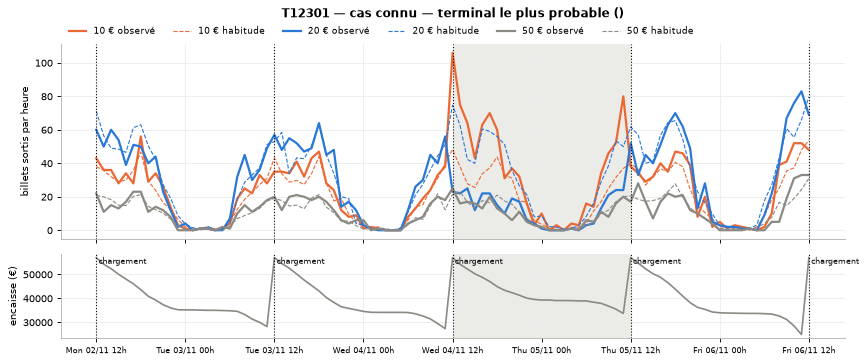

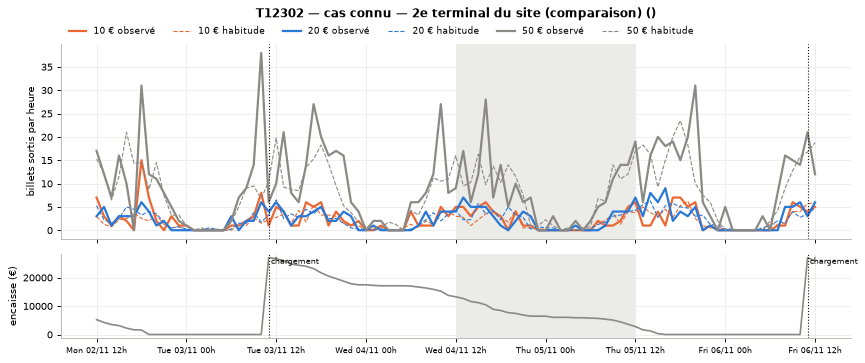

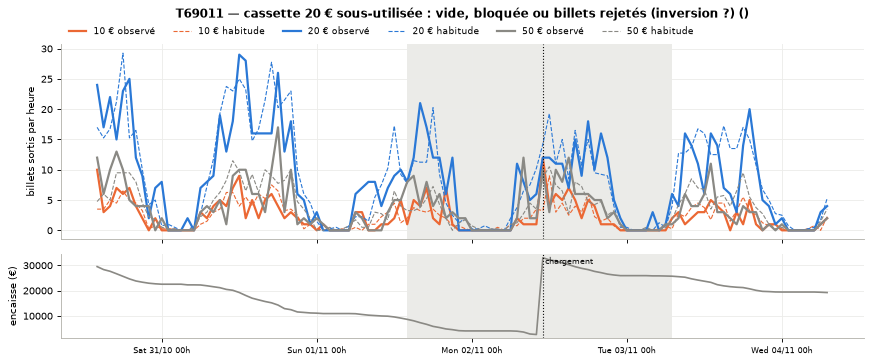

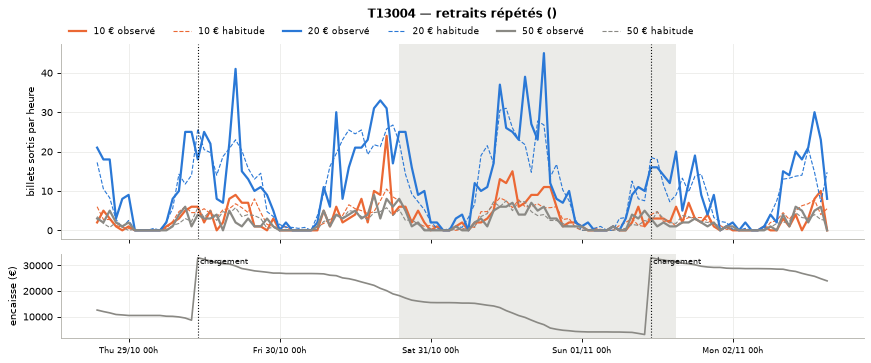

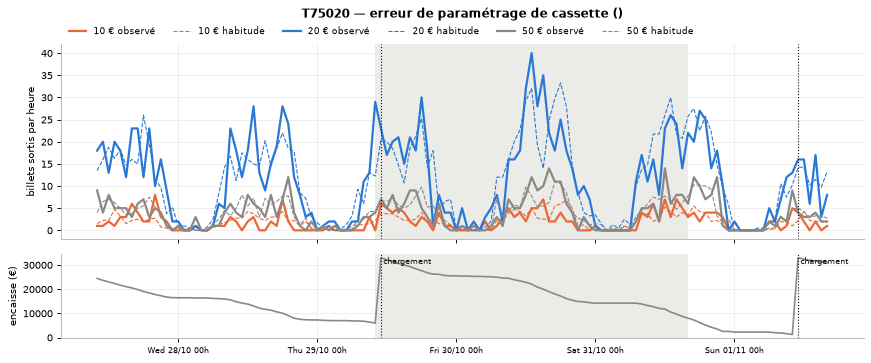

In [9]:
def tracer_coupures(terminal, d0, d1, titre=None):
    hab = habitude.loc[terminal]
    g = grille[grille["num_automate"] == terminal].set_index("ts")
    zone = g[(g.index >= d0 - pd.Timedelta(days=2)) & (g.index <= d1 + pd.Timedelta(days=1))]
    ref = g[g.index < DEBUT]
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
    coupures = sorted(set(hab[["val_ref_pos{}".format(k) for k in POSITIONS]].dropna().astype(int)))
    for c in coupures:
        cols = ["nb_billets_pos{}".format(k) for k in POSITIONS if hab["val_ref_pos{}".format(k)] == c]
        obs = zone[cols].sum(axis=1)
        moy = ref[cols].sum(axis=1).groupby([ref.index.dayofweek, ref.index.hour]).mean()
        attendu = [moy.get((t.dayofweek, t.hour), np.nan) for t in zone.index]
        couleur = COULEUR_COUPURE.get(c, ENCRE)
        ax.plot(zone.index, obs, color=couleur, linewidth=2, label="{} € observé".format(c))
        ax.plot(zone.index, attendu, color=couleur, linewidth=1, linestyle="--", label="{} € habitude".format(c))
    ax.axvspan(d0, d1, color=GRIS_CLAIR, alpha=0.5, linewidth=0)
    ax2.axvspan(d0, d1, color=GRIS_CLAIR, alpha=0.5, linewidth=0)
    ax2.plot(zone.index, zone["encaisse_max_heure"].ffill(), color=GRIS, linewidth=1.5)
    ax2.set_ylabel("encaisse (€)")
    for t in zone.index[zone["nb_recharges"] > 0]:
        for a in (ax, ax2):
            a.axvline(t, color=ENCRE, linewidth=1, linestyle=":")
        ax2.annotate("chargement", (t, 1), xycoords=("data", "axes fraction"), xytext=(2, -9),
                     textcoords="offset points", fontsize=7, color=ENCRE)
    ax.set_ylabel("billets sortis par heure")
    ax.set_title(titre or "{} — billets sortis par coupure".format(terminal), pad=24)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m %Hh"))
    ax.legend(ncol=6, fontsize=8, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0))
    for e in ax2.get_xticklabels():
        e.set_fontsize(7)
    fig.tight_layout()
    plt.show()


a_tracer = []
if len(candidats):
    a_tracer.append((candidats.iloc[0]["num_automate"], pd.Timestamp(CAS_CONNU["debut"]),
                     pd.Timestamp(CAS_CONNU["fin"]), "cas connu — terminal le plus probable"))
    if len(candidats) > 1:
        a_tracer.append((candidats.iloc[1]["num_automate"], pd.Timestamp(CAS_CONNU["debut"]),
                         pd.Timestamp(CAS_CONNU["fin"]), "cas connu — 2e terminal du site (comparaison)"))
for _, ev in evenements.head(4).iterrows() if len(evenements) else []:
    if ev["num_automate"] not in [a[0] for a in a_tracer]:
        a_tracer.append((ev["num_automate"], ev["alerte du"], ev["au"], ev["lecture proposée"]))
for terminal, d0, d1, libelle in a_tracer:
    tracer_coupures(terminal, d0, d1, "{} — {} ({})".format(terminal, libelle, infos.loc[terminal, "ville"]))

## 9. Synthèse et export

In [10]:
afficher_chiffres({"terminal analysés": grille["num_automate"].nunique(),
                   "événements": len(evenements),
                   "inversions 10/20 possibles": int((evenements["lecture proposée"] == "inversion 10 € / 20 € possible").sum())
                   if len(evenements) else 0,
                   "erreurs de paramétrage": int(evenements["lecture proposée"].str.startswith("erreur").sum())
                   if len(evenements) else 0,
                   "cassettes vides ou bloquées": int((evenements["lecture proposée"] == "cassette vide ou bloquée").sum())
                   if len(evenements) else 0},
                  "Synthèse")
if len(evenements):
    for _, ev in evenements.head(10).iterrows():
        texte = "<b>{}</b> ({}) : {}, du {} au {} ; position {} sortie à {:.0f} % au lieu de {:.0f} %".format(
            ev["num_automate"], ev["ville"], ev["lecture proposée"], formater(ev["alerte du"]), formater(ev["au"]),
            ev["position en cause"], ev["part observée %"], ev["part habituelle %"])
        if ev["chargement au début"] != "non":
            texte += " ; chargement au début : {}".format(ev["chargement au début"])
        if not pd.isna(ev["perte si inversion 10/20 (€)"]) and ev["lecture proposée"].startswith("inversion"):
            texte += " ; perte estimée si l'inversion est confirmée : {} €".format(formater(ev["perte si inversion 10/20 (€)"]))
        display(HTML(CSS + "<div class='note'>{}</div>".format(texte)))
if DATASET_SORTIE_EVENEMENTS and len(evenements):
    import dataiku
    sortie = evenements.copy()
    for c in ["alerte du", "au"]:
        sortie[c] = sortie[c].astype(str)
    dataiku.Dataset(DATASET_SORTIE_EVENEMENTS).write_with_schema(sortie)

## 10. Zoom : terminal du code regate choisi, sur la période donnée
Uniquement les terminaux dont le `code_site_implantation` commence par le préfixe de la section 1, et uniquement les
alertes qui touchent la période donnée (élargie de `jours_autour` jours de chaque côté). La date maximale des
données indique si la période est bien couverte.

In [11]:
if not CAS_CONNU:
    afficher_titre("Section non exécutée : CAS_CONNU est vide (section 1)",
                   "Renseigner en section 1, par exemple : CAS_CONNU = {\"debut\": \"AAAA-MM-JJ HH:MM\", "
                   "\"fin\": \"AAAA-MM-JJ HH:MM\", \"prefixe_site\": \"123\", \"perte_declaree\": 5000, "
                   "\"jours_autour\": 2}, puis relancer les cellules à partir de la section 1.")
if CAS_CONNU:
    z0, z1 = pd.Timestamp(CAS_CONNU["debut"]), pd.Timestamp(CAS_CONNU["fin"])
    marge = pd.Timedelta(days=CAS_CONNU.get("jours_autour", 2))
    pref = str(CAS_CONNU["prefixe_site"]).strip().lstrip("0")
    codes = infos["code_site_implantation"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str.lstrip("0")
    terminal_zoom = codes[codes.str.startswith(pref)].index
    derniere = brut[brut["num_automate"].isin(terminal_zoom)].groupby("num_automate")["ts"].max()
    afficher_chiffres({"code regate commençant par": pref,
                       "terminal concernés": len(terminal_zoom),
                       "période donnée": "{} → {}".format(z0.strftime("%d/%m %Hh"), z1.strftime("%d/%m %Hh")),
                       "date max des données (tous terminal)": brut["ts"].max().strftime("%d/%m/%Y %Hh"),
                       "date max des données (ces terminaux)": derniere.max().strftime("%d/%m/%Y %Hh") if len(derniere) else "–",
                       "période couverte": "oui" if len(derniere) and derniere.max() >= z1 - pd.Timedelta(hours=1)
                       else "NON : données arrêtées avant la fin de la période"},
                      "Zoom code regate {} du {} au {}".format(pref, z0.strftime("%d/%m"), z1.strftime("%d/%m")))

    # dernière date de chaque terminal : un terminal qui s'arrête avant la période ne peut pas être analysé
    table_dates = pd.DataFrame({"num_automate": derniere.index,
                                "dernière heure présente": derniere.values}).sort_values("dernière heure présente")
    afficher_tableau(table_dates, "Dernière heure présente dans les données, par terminal")

    # événements de la section 6 qui touchent la période
    if len(evenements):
        ev_zoom = evenements[evenements["num_automate"].isin(terminal_zoom) &
                             (evenements["au"] >= z0 - marge) & (evenements["alerte du"] <= z1 + marge)]
    else:
        ev_zoom = pd.DataFrame()
    afficher_tableau(ev_zoom.drop(columns=["force"]) if len(ev_zoom) else ev_zoom,
                     "Événements de ces terminaux autour de la période ({} événement(s))".format(len(ev_zoom)),
                     "Événements de la section 6 dont les dates chevauchent la période donnée, élargie de {} jours."
                     .format(marge.days))

    # fenêtres de 24 h en alerte, heure par heure, pour ces terminaux et cette période
    fen_zoom = analyse[analyse["num_automate"].isin(terminal_zoom) & (analyse["ts"] >= z0 - marge) &
                       (analyse["ts"] <= z1 + marge) & analyse["alerte"]].copy()
    if len(fen_zoom):
        fen_zoom["signaux"] = fen_zoom.apply(lambda l: ", ".join(nom for nom, cle in SIGNAUX if l[cle]), axis=1)
        fen_zoom["fenêtre de 24 h"] = fen_zoom["ts"].apply(
            lambda t: "{} → {}".format((t - pd.Timedelta(hours=FENETRE_HEURES - 1)).strftime("%d/%m %Hh"),
                                       t.strftime("%d/%m %Hh")))
        en_vol = fen_zoom[["signal_sur", "signal_sous", "signal_reactivation"]].any(axis=1)
        fen_zoom["k"] = np.where(en_vol, fen_zoom["position_volume"], fen_zoom["position_ecart"]).astype(int)
        fen_zoom["cassette en cause"] = fen_zoom.apply(lambda l: "p{} ({} €)".format(
            l["k"], formater(habitude.loc[l["num_automate"], "val_ref_pos{}".format(l["k"])])).replace(".0 €", " €"),
            axis=1)
        fen_zoom["billets sortis"] = fen_zoom.apply(lambda l: l["nb_billets_pos{}".format(l["k"])], axis=1)
        fen_zoom["billets habituels"] = fen_zoom.apply(lambda l: l["attendu_pos{}".format(l["k"])], axis=1)
        fen_zoom = fen_zoom[["num_automate", "fenêtre de 24 h", "signaux", "cassette en cause", "billets sortis",
                             "billets habituels", "score_cassettes", "score_volume", "nb_retraits_repetes_10min"]]
    afficher_tableau(fen_zoom, "Fenêtres de 24 h en alerte pour ces terminaux ({} fenêtre(s))".format(len(fen_zoom)),
                     "Une ligne par heure de fin de fenêtre ; billets sortis et habituels de la cassette en cause "
                     "sur les 24 h de la fenêtre.", max_lignes=60)

num_automate,dernière heure présente
T12303,08/11 22h
T12305,08/11 22h
T12301,08/11 23h
T12302,08/11 23h
T12304,08/11 23h
T12306,08/11 23h


num_automate,site,ville,lecture proposée,signaux,alerte du,au,24 h les plus anormales,chargement au début,chargement à la fin,position en cause,billets sortis (24 h),billets habituels,ratio,part habituelle %,part observée %,score cassettes,retraits répétés,attendus,perte si inversion 10/20 (€),perte paramétrage (€)
T12301,12301,,inversion 10 € / 20 € possible,"répartition, retraits répétés",03/11 17h,05/11 21h,04/11 12h → 05/11 11h,04/11 12h (32 040 €),05/11 12h (25 580 €),p1 (10 €),862,493.0,1.7,33.0,62.7,28.4,26,5.9,5 740,–


num_automate,fenêtre de 24 h,signaux,cassette en cause,billets sortis,billets habituels,score_cassettes,score_volume,nb_retraits_repetes_10min
T12301,03/11 17h → 04/11 16h,répartition,p1 (10 €),661.0,468.0,4.7,0.0,11.0
T12301,03/11 18h → 04/11 17h,répartition,p1 (10 €),688.0,471.5,6.3,0.0,12.0
T12301,03/11 19h → 04/11 18h,répartition,p1 (10 €),701.0,471.2,8.3,0.0,13.0
T12301,03/11 20h → 04/11 19h,répartition,p1 (10 €),704.0,476.2,9.8,0.0,13.0
T12301,03/11 21h → 04/11 20h,répartition,p1 (10 €),717.0,489.8,11.6,0.0,14.0
T12301,03/11 22h → 04/11 21h,répartition,p1 (10 €),737.0,488.2,12.4,0.0,15.0
T12301,03/11 23h → 04/11 22h,répartition,p1 (10 €),745.0,495.2,13.4,0.0,15.0
T12301,04/11 00h → 04/11 23h,répartition,p1 (10 €),739.0,496.5,13.5,0.0,15.0
T12301,04/11 01h → 05/11 00h,répartition,p1 (10 €),748.0,497.5,14.0,0.0,16.0
T12301,04/11 02h → 05/11 01h,répartition,p1 (10 €),746.0,497.5,14.0,0.0,16.0
